# Insolation: sun hours on the ground and on facades

This notebook computes hours of direct sunlight among buildings of known height with
`get_insolation` (ground receivers) and `get_facade_insolation` (facade points per floor):

1. sun-hour zones for a single day (equinox and summer solstice);
2. a period (22 April – 22 August) with the longest continuous sunlit period on the worst day;
3. the effect of terrain given as a GeoDataFrame of polygons;
4. facade insolation per floor and a check against a continuous-insolation norm.

The example buildings (Vasilyevsky Island, Saint Petersburg, 59.96° N) have a `storeys_count` column; heights are
storeys × 3 m. The method is described on the [insolation page](../insolation.rst).

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd

buildings = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636 (UTM 36N), metres
# 0 storeys means "unknown" in this dataset; such buildings get default_height below
buildings["storeys_count"] = buildings["storeys_count"].where(buildings["storeys_count"] > 0)
HEIGHTS = dict(height_column=None, storeys_column="storeys_count", storey_height=3.0, default_height=3.0)
buildings[["storeys_count", "geometry"]].describe()

,storeys_count
count,4100.000000
mean,3.243902
std,3.430774
min,1.000000
25%,1.000000
50%,1.000000
75%,5.000000
max,24.000000


In [3]:
import matplotlib.pyplot as plt
import numpy as np


def map_axes(ax, bounds, step=100):
    """Show `bounds` (x0, y0, x1, y1 in metres) with axes in metres from the lower-left corner."""
    x0, y0, x1, y1 = bounds
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xticks(x0 + np.arange(0, x1 - x0 + 1, step), [f"{v:g}" for v in np.arange(0, x1 - x0 + 1, step)])
    ax.set_yticks(y0 + np.arange(0, y1 - y0 + 1, step), [f"{v:g}" for v in np.arange(0, y1 - y0 + 1, step)])
    ax.set_xlabel("x, m")
    ax.set_ylabel("y, m")
    ax.tick_params(labelsize=8)

## 1. Study area

A 500 × 400 m residential area with courtyards. All buildings within 300 m of it are passed to the functions,
because buildings outside the area also cast shadows into it.

In [4]:
import shapely

from objectnat import get_facade_insolation, get_insolation

area = shapely.box(344750, 6649850, 345250, 6650250)  # in the CRS of the buildings
scene = buildings[buildings.intersects(area.buffer(300))]
shown = scene.clip(area.buffer(1))
print(f"{len(scene)} buildings in the scene, {len(shown)} in the area")

171 buildings in the scene, 50 in the area


## 2. One day

`date` is a single day. Receivers are placed every `grid_step` metres outside footprints, and the sun position is
sampled every `time_step_min` minutes. The result has one zone per class of daily sun hours (`hour_breaks`); class
`0` is ground with no direct sun at all. `attrs` hold the simulated days and the day length.

In [5]:
import time

days = {"2026-03-21": "21 March", "2026-06-21": "21 June"}
zones = {}
for day in days:
    start = time.perf_counter()
    zones[day] = get_insolation(scene, day, area=area, grid_step=2, time_step_min=10, **HEIGHTS)
    print(f"{day}: {time.perf_counter() - start:.1f} s, day length {zones[day].attrs['day_length_hours']:.1f} h")

summary = zones["2026-03-21"].assign(area_ha=lambda z: z.area / 1e4)[["label", "sun_hours_min", "sun_hours_max", "area_ha"]]
summary.round(2)

2026-03-21: 0.9 s, day length 12.2 h


2026-06-21: 1.0 s, day length 18.7 h


,label,sun_hours_min,sun_hours_max,area_ha
0,0,0.0,0.0,0.79
1,<1,0.0,1.0,1.04
2,1–2,1.0,2.0,1.24
3,2–3,2.0,3.0,1.91
4,3–4,3.0,4.0,2.09
5,4–6,4.0,6.0,3.91
6,6–8,6.0,8.0,2.97
7,≥8,8.0,inf,2.37


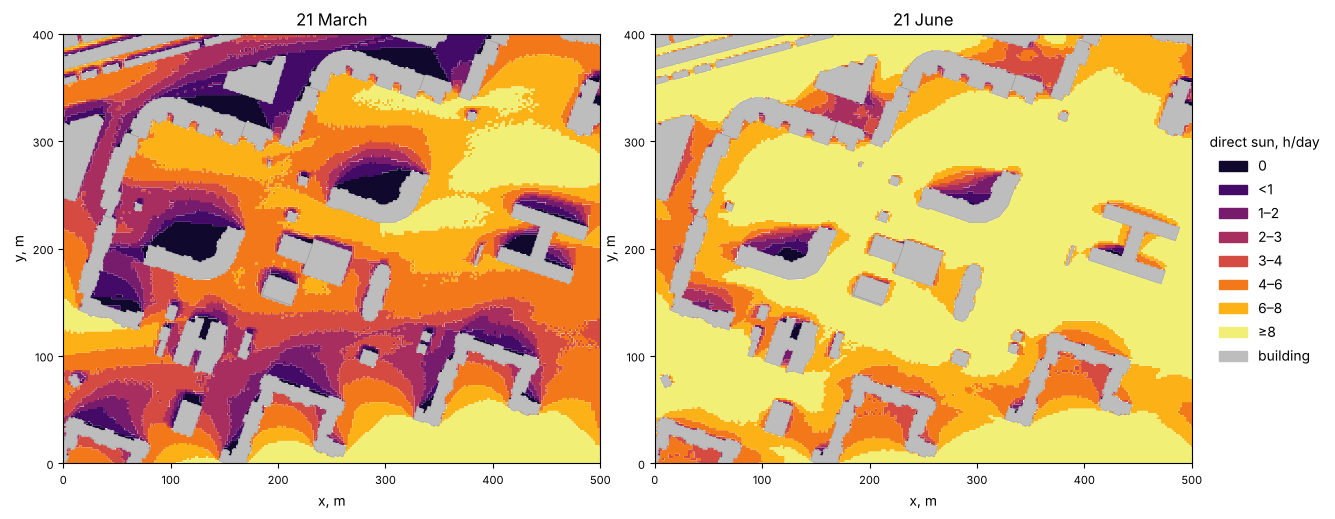

In [6]:
from matplotlib.patches import Patch

labels = ["0", "<1", "1–2", "2–3", "3–4", "4–6", "6–8", "≥8"]
cmap = plt.get_cmap("inferno")
colors = {lab: cmap(0.08 + 0.87 * k / (len(labels) - 1)) for k, lab in enumerate(labels)}

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, (day, title) in zip(axs, days.items()):
    z = zones[day]
    z.plot(ax=ax, color=[colors[lab] for lab in z["label"]], linewidth=0)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    ax.set_title(title)
handles = [Patch(color=colors[lab], label=lab) for lab in labels] + [Patch(color="#bdbdbd", label="building")]
axs[1].legend(handles=handles, title="direct sun, h/day", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

## 3. A period and the worst day

`date=(start, end)` simulates every `day_step`-th day of the period and its last day. With `return_receivers=True`
the receiver points carry `sun_hours` (mean over the simulated days), `min_sun_hours` (worst day) and
`max_continuous_hours` (longest continuous sunlit period on the worst day), which insolation norms usually limit.

In [7]:
period_zones, receivers = get_insolation(
    scene, ("2026-04-22", "2026-08-22"), area=area, grid_step=2, day_step=7, return_receivers=True, **HEIGHTS
)
print(len(receivers.attrs["days"]), "simulated days:", receivers.attrs["days"][0], "...", receivers.attrs["days"][-1])
receivers[["sun_hours", "min_sun_hours", "max_continuous_hours"]].describe().round(2)

19 simulated days: 2026-04-22 ... 2026-08-22


,sun_hours,min_sun_hours,max_continuous_hours
count,41207.00,41207.00,41207.00
mean,8.11,6.59,5.65
std,3.04,2.96,2.89
min,0.00,0.00,0.00
25%,5.93,4.33,3.33
50%,8.59,7.00,5.50
75%,10.70,9.17,8.17
max,14.32,12.67,12.67


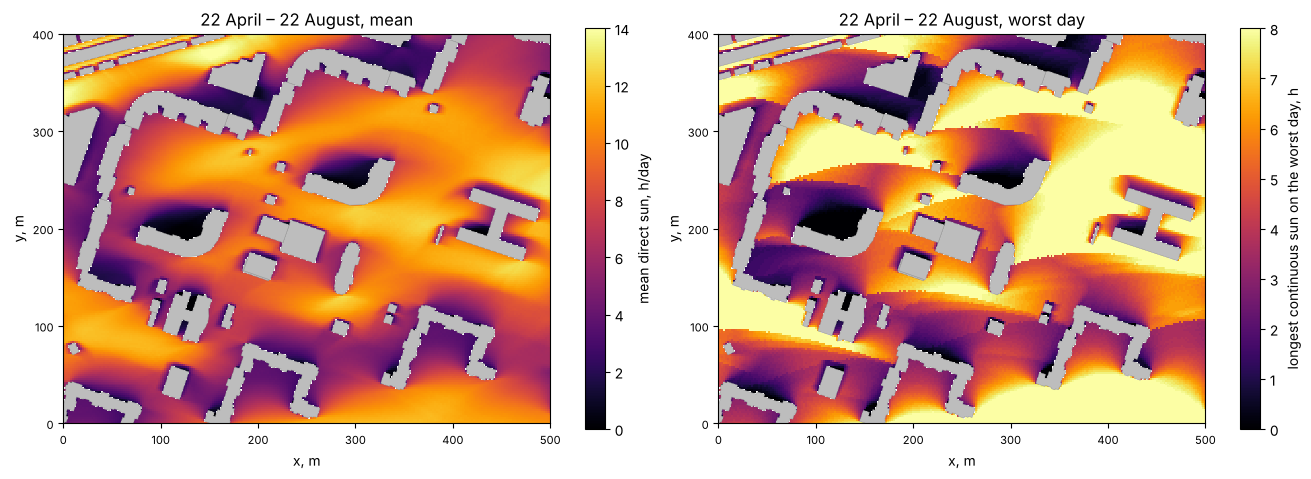

In [8]:
def raster(ax, points, values, step, **kw):
    """Draw regular-grid point values as an image."""
    xy = shapely.get_coordinates(points)
    i = np.round((xy[:, 0] - xy[:, 0].min()) / step).astype(int)
    j = np.round((xy[:, 1] - xy[:, 1].min()) / step).astype(int)
    img = np.full((j.max() + 1, i.max() + 1), np.nan)
    img[j, i] = values
    x0, y0 = xy[:, 0].min() - step / 2, xy[:, 1].min() - step / 2
    return ax.imshow(img, origin="lower", extent=(x0, x0 + img.shape[1] * step, y0, y0 + img.shape[0] * step),
                     interpolation="nearest", **kw)


fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, col, label, vmax in [
    (axs[0], "sun_hours", "mean direct sun, h/day", 14),
    (axs[1], "max_continuous_hours", "longest continuous sun on the worst day, h", 8),
]:
    im = raster(ax, receivers.geometry.values, receivers[col].to_numpy(), 2.0, cmap="inferno", vmin=0, vmax=vmax)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    fig.colorbar(im, ax=ax, shrink=0.8, label=label)
axs[0].set_title("22 April – 22 August, mean")
axs[1].set_title("22 April – 22 August, worst day")
plt.show()

Share of the open ground in the area that receives at least 3 h of continuous sun on every simulated day:

In [9]:
share = (receivers["max_continuous_hours"] >= 3).mean()
print(f"{share:.0%} of the receivers")

81% of the receivers


## 4. Terrain

Terrain can be a GeoDataFrame of polygons with heights (rasterized with `terrain_cell` cells), a GeoTIFF path or a
`(heights, transform, crs)` tuple. Here a synthetic hill, 26 m high, is described by nested circles at 2 m
intervals; a base polygon at 0 m covers the rest of the scene, because places without a polygon count as no data.
Buildings stand on the terrain and receivers lie on it.

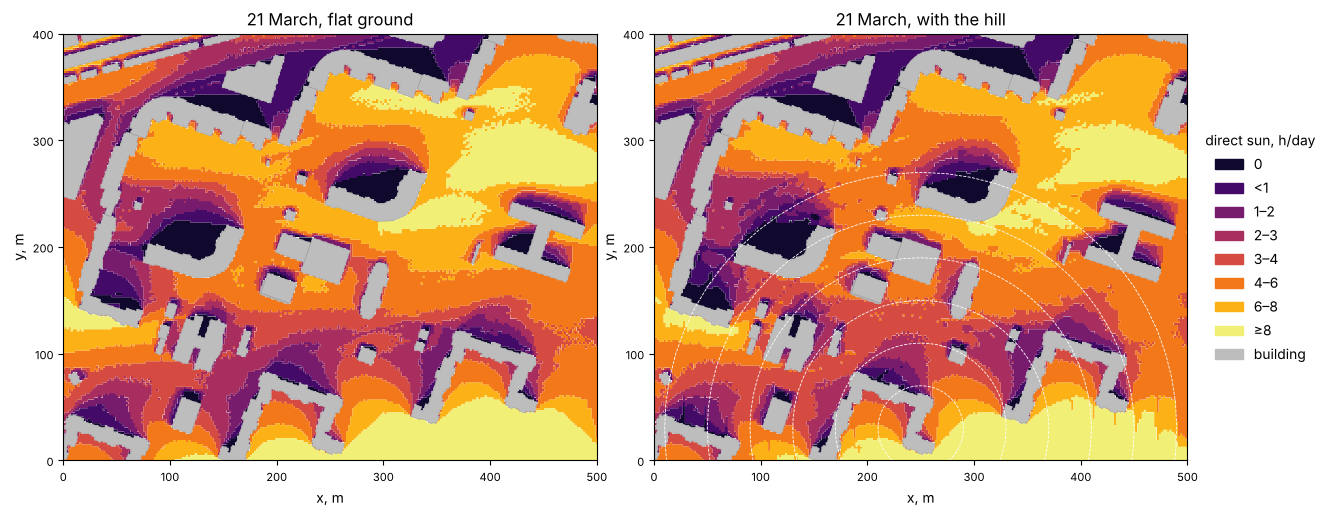

,"flat, ha","hill, ha"
label,,
0,0.79,0.86
<1,1.04,0.98
1–2,1.24,1.23
2–3,1.91,1.84
3–4,2.09,2.49
4–6,3.91,4.26
6–8,2.97,2.74
≥8,2.37,1.94


In [10]:
import pandas as pd

centre = shapely.Point(345000, 6649880)
hill = gpd.GeoDataFrame(
    {"height": [2.0 * (k + 1) for k in range(13)]},
    geometry=[centre.buffer(r) for r in range(260, 0, -20)],
    crs=buildings.crs,
)
base = gpd.GeoDataFrame({"height": [0.0]}, geometry=[area.buffer(400)], crs=buildings.crs)
terrain = pd.concat([base, hill], ignore_index=True)

flat = zones["2026-03-21"]
hilly = get_insolation(scene, "2026-03-21", area=area, grid_step=2, terrain=terrain, terrain_cell=5, **HEIGHTS)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
for ax, z, title in [(axs[0], flat, "21 March, flat ground"), (axs[1], hilly, "21 March, with the hill")]:
    z.plot(ax=ax, color=[colors[lab] for lab in z["label"]], linewidth=0)
    shown.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, area.bounds)
    ax.set_title(title)
hill.iloc[1::2].boundary.clip(area).plot(ax=axs[1], color="white", lw=0.6, ls="--")
axs[1].legend(handles=handles, title="direct sun, h/day", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

compare = pd.DataFrame({"flat, ha": flat.set_index("label").area / 1e4, "hill, ha": hilly.set_index("label").area / 1e4})
compare.reindex(labels).round(2)

## 5. Facades per floor

`get_facade_insolation` places points every `spacing` metres along the walls of the buildings intersecting `area`,
on every floor at `window_height` above the floor level. The sun counts while it is in front of the facade and the
ray towards it is clear. `norm_hours` adds `meets_norm`, the check of the longest continuous sunlit period.

The example uses 22 April and 2.5 h of continuous sun as the norm value; use the calculation day and the value of
the norm that applies to the project (for Russia, SanPiN 1.2.3685-21).

In [11]:
target = shapely.box(344900, 6649950, 345150, 6650200)
facades = get_facade_insolation(scene, "2026-04-22", area=target, spacing=3, window_height=1.2, norm_hours=2.5, **HEIGHTS)
print(len(facades), "facade points on", facades["building"].nunique(), "buildings")
facades.drop(columns="geometry").head()

14945 facade points on 25 buildings


,building,floor,height,facade_azimuth,sun_hours,min_sun_hours,max_continuous_hours,meets_norm
0,95,1,1.2,291.080748,2.500000,2.500000,2.166667,False
1,95,2,4.2,291.080748,2.666667,2.666667,2.333333,False
2,95,3,7.2,291.080748,2.833333,2.833333,2.500000,True
3,95,4,10.2,291.080748,2.833333,2.833333,2.500000,True
4,95,5,13.2,291.080748,3.000000,3.000000,2.666667,True


In [12]:
by_floor = facades.groupby("floor").agg(
    points=("meets_norm", "size"), meets_norm=("meets_norm", "mean"), continuous_h=("max_continuous_hours", "median")
)
by_floor["meets_norm"] = (100 * by_floor["meets_norm"]).round(1)
by_floor.rename(columns={"meets_norm": "meets norm, %", "continuous_h": "median continuous sun, h"})

,points,"meets norm, %","median continuous sun, h"
floor,,,
1,1238,53.0,2.500000
2,969,55.9,2.833333
3,949,58.0,3.000000
4,949,59.0,3.166667
5,949,60.1,3.333333
6,949,61.6,3.500000
7,949,62.7,3.666667
8,949,64.2,3.833333
9,949,66.3,4.000000


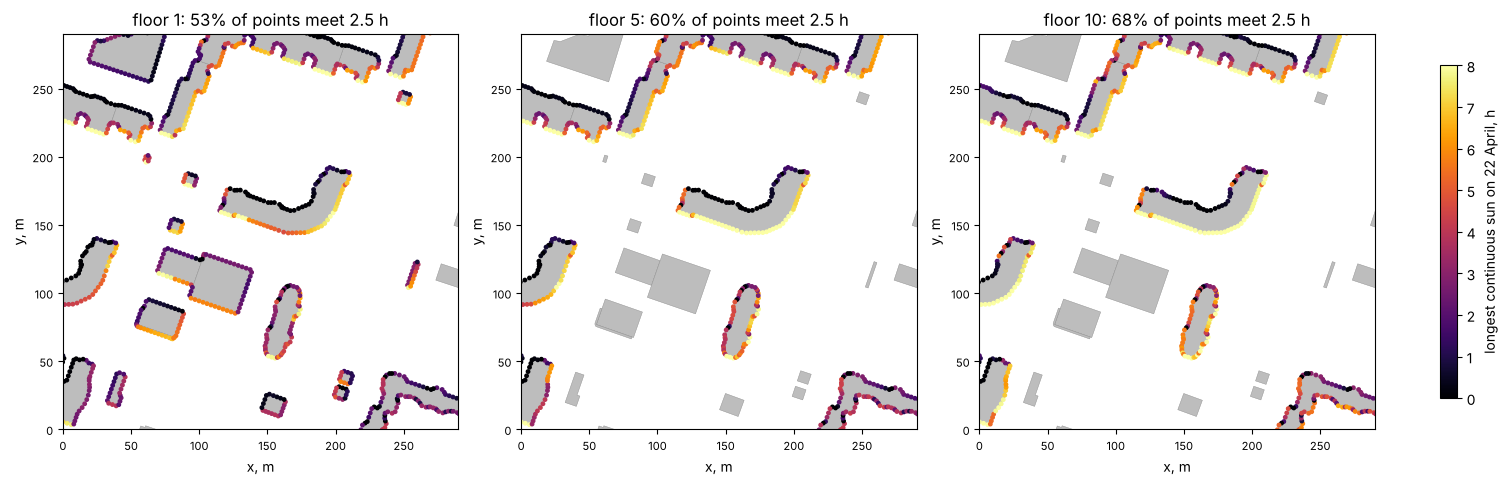

In [13]:
from matplotlib import colors as mcolors

norm = mcolors.Normalize(0, 8)
x0, y0, x1, y1 = target.buffer(20).bounds
fig, axs = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, floor in zip(axs, [1, 5, 10]):
    sub = facades[facades["floor"] == floor]
    scene.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    sub.plot(ax=ax, column="max_continuous_hours", cmap="inferno", norm=norm, markersize=6)
    map_axes(ax, (x0, y0, x1, y1), step=50)
    ax.set_title(f"floor {floor}: {sub['meets_norm'].mean():.0%} of points meet 2.5 h")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="inferno"), ax=axs, shrink=0.7,
             label="longest continuous sun on 22 April, h")
plt.show()

Buildings with the lowest share of facade points meeting the norm on the ground floor:

In [14]:
ground = facades[facades["floor"] == 1]
per_building = ground.groupby("building")["meets_norm"].agg(["size", "mean"]).rename(
    columns={"size": "points", "mean": "share meeting norm"}
)
per_building.sort_values("share meeting norm").head(5).round(2)

,points,share meeting norm
building,,
1274,59,0.22
102,95,0.37
408,20,0.40
2841,22,0.41
95,203,0.48


## Limitations

Roofs are flat; balconies, loggias, window reveals and trees are not modelled, and only direct sunlight is
counted. Values are multiples of `time_step_min`. See the [insolation page](../insolation.rst) for details.